In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
%matplotlib inline
from sklearn.datasets import load_iris, load_breast_cancer
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import scorecardpy as sc
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [2]:
from woe_functions import (
    DecisionTree,
    fuzzy_fixed_alfas,
    grado_pertenencia_padre_func,
    assign_woe,
    plot_grados_pertenencia_fuzzy_woe_fixed_alfas,
    FuzzyDecisionTree,
    print_fuzzy_tree,
    plot_membership_functions
)

## Carga de datos

In [3]:
country = 'Taiwan'
nombre_carpeta = 'Datasets Artículo'

if country == 'Australia':
    df_data = pd.read_csv(nombre_carpeta + '/australian_credit.csv')
elif country == 'Germany':
    df_data = pd.read_csv(nombre_carpeta + '/german_credit.csv')
elif country == 'Japan':
    df_data = pd.read_csv(nombre_carpeta + '/japan_credit.csv')
elif country == 'Taiwan':
    df_data = pd.read_csv(nombre_carpeta + '/taiwan_credit.csv')
elif country == 'Poland':
    df_data = pd.read_csv(nombre_carpeta + '/polish_credit.csv')

elif country == 'credit_card':
    df_data = pd.read_csv(nombre_carpeta + '/credit_card.csv')
elif country == 'cs_accepts':
    df_data = pd.read_csv(nombre_carpeta + '/cs_accepts.csv')
elif country == 'give_me_some_credit':
    df_data = pd.read_csv(nombre_carpeta + '/give_me_some_credit.csv')
elif country == 'hmeq':
    df_data = pd.read_csv(nombre_carpeta + '/hmeq.csv')
elif country == 'kdd_2010':
    df_data = pd.read_csv(nombre_carpeta + '/kdd_2010.csv', encoding="latin-1")
    df_data = df_data.rename(columns={'TARGET': 'target'})
elif country == 'loan_data':
    df_data = pd.read_csv(nombre_carpeta + '/loan_data.csv')
elif country == 'mortgage':
    df_data = pd.read_csv(nombre_carpeta + '/mortgage.csv')

    
df_data

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,30000,1,2,2,37,4,3,2,-1,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [4]:
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

In [5]:
df_data.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [6]:
df_data.columns

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'target'],
      dtype='object')

In [7]:
if country == 'Australia':
    variables_numericas = ['A2', 'A3', 'A7', 'A10', 'A13', 'A14'] # 6
    variables_categoricas = ['A1', 'A4', 'A5', 'A6', 'A8', 'A9', 'A11', 'A12'] # 8
elif country == 'Germany':
    variables_numericas = ['duration', 'amount', 'age'] # 3
#     variables_categoricas = ['balance', 'previous', 'purpose', 'savings',
#            'length_employment', 'instalment', 'sex_marital', 'guarantors',
#            'duration_address', 'most_valuable', 'concurrent_credits',
#            'apartment', 'num_credits', 'occupation', 'dependents', 'telephone',
#            'foreign'] # 17
    variables_categoricas = ['balance', 'previous', 'purpose', 'savings',
           'l_employment', 'instalment', 'sex_marital', 'guarantors',
           'durat_address', 'most_valuable', 'concu_credits',
           'apartment', 'num_credits', 'occupation', 'dependents', 'telephone',
           'foreign'] # 17
elif country == 'Japan':
    variables_numericas = ['A2', 'A3', 'A8', 'A11', 'A14', 'A15'] # 6
    variables_categoricas = ['A1', 'A4', 'A5', 'A6', 'A7', 'A9', 'A10', 'A12', 'A13'] # 9
elif country == 'Taiwan':
    variables_numericas = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'] # 14
    variables_categoricas = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6'] # 9
# elif country == 'Poland':
#     variables_numericas = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11',
#        'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21',
#        'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30', 'X31',
#        'X32', 'X33', 'X34', 'X35', 'X36', 'X37', 'X38', 'X39', 'X40', 'X41',
#        'X42', 'X43', 'X44', 'X45', 'X46', 'X47', 'X48', 'X49', 'X50', 'X51',
#        'X52', 'X53', 'X54', 'X55', 'X56', 'X57', 'X58', 'X59', 'X60', 'X61',
#        'X62', 'X63', 'X64'] # 64
#     variables_categoricas = [] # 0
elif country == 'Poland':
    variables_numericas = ['X6', 'X7', 'X8', 'X9', 'X24', 'X27', 'X29', 'X34', 'X46', 'X55', 'X56',
       'X57', 'X58', 'X60', 'X61', 'X62', 'X63', 'X64'] # 18
    variables_categoricas = [] # 0
    
    
elif country == 'credit_card':
    variables_numericas = ['reports', 'age', 'income', 'dependents', 'months', 'active', 'majorcards'] # 7
    variables_categoricas = ['owner', 'selfemp'] # 2
elif country == 'cs_accepts':
    variables_numericas = ['CHILD', 'PERS_H', 'AGE', 'TMADD', 'TMJOB1', 'NMBLOAN',
       'FINLOAN', 'INCOME', 'INC', 'LOANS', 'CASH'] # 11
    variables_categoricas = ['TEL', 'TITLE', 'EC_CARD', 'INC1', 'BUREAU',
       'LOCATION', 'REGN', 'DIV', 'STATUS', 'PRODUCT', 'RESID', 'NAT', 'PROF', 'CAR', 'CARDS'] # 15
elif country == 'give_me_some_credit':
    variables_numericas = ['RevolvingUse', 'age', 'NTime3059Days', 'DebtRatio', 'MonthlyIncome',
       'NCreditLoans', 'NTime90Days', 'NRealLoanLine', 'NTime6089Days', 'Dependents'] # 10
    variables_categoricas = [] # 0
elif country == 'hmeq':
    variables_numericas = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC'] # 10
    variables_categoricas = ['REASON', 'JOB'] # 2
elif country == 'kdd_2010':
    variables_numericas = [
    'PAYMENT_DAY',
    'QUANT_DEPEND',
    'EDUCAT_LEV2',    
    'MONTH_INCOME',
    'OTHER_INCOMES',
    'QUANT_BANK_AC',
    'QUANT_SP_BANK',
    'ASSETS_VALUE',
    'QUANT_CARS',
    'MONTHS_RESID',
    'MONTHS_IN_JOB',
    'AGE'
    ]  # 12
    variables_categoricas = [
    'APPLICATION',
    'POSTAL_ADDRES',
    'SEX',
    'MARITAL_STAT',
    'STATE_BIRTH',
    'CITY_OF_BIRTH',
    'NACIONALITY',
    'RESID_STATE',
    'RESID_CITY',
    'RESID_BOROUGH',
    'RESID_PHO',
    'RESI_PHO_AREA',
    'RESID_TYPE',
    'EMAIL',
    'VISA',
    'MASTERCARD',
    'DINERS',
    'AMERICAN_EXP',
    'OTHER_CARDS',
    'COMPANY',
    'PROF_STATE',
    'PROF_CITY',
    'PROF_BOROUGH',
    'PROF_PHONE',
    'PROF_PHO_AREA',
    'PROF_CODE',
    'OCCUPATION',
    'MATE_PROF_COD',
    'PRODUCT',
    'RESID_ZIP_3',
    'PROF_ZIP_3',
    ] # 31
    
elif country == 'loan_data':
    variables_numericas = ['YOB', 'NKID', 'DEP', 'SINC', 'DAINC', 'DHVAL', 'DMORT', 'DOUTM', 'DOUTL', 'DOUTHP', 'DOUTCC'] # 11
    variables_categoricas = ['PHON', 'AES', 'RES'] # 3
elif country == 'mortgage':
    variables_numericas = ['orig_time', 'first_time', 'mat_time', 'balance_time', 'LTV_time',
       'int_rate_time', 'hpi_time', 'gdp_time', 'uer_time', 'blce_og_time',
       'FICO_og_time', 'LTV_og_time', 'Int_Rt_og_time', 'hpi_og_time'] # 14
    variables_categoricas = ['Rty_CO_og_time', 'Rty_PU_og_time', 'Rty_SF_og_time', 'inv_og_time'] # 4

In [8]:
print(f"Número de observaciones: {df_data['target'].count()}")
print(f"Ratio: {df_data['target'].sum()/df_data['target'].count()}")

Número de observaciones: 30000
Ratio: 0.2212


In [9]:
df_data

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,target
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,30000,1,2,2,37,4,3,2,-1,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [10]:
variables_numericas

['LIMIT_BAL',
 'AGE',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6']

In [11]:
variable = 'AGE'

x_prueba = df_data[variable].values
y_prueba = df_data['target'].values

# Gráficos para el artículo

## Árbol nítido

In [12]:
tree = DecisionTree(criterion='gini', max_depth=2)
tree.fit(x_prueba, y_prueba)
tree.print_tree()

NODE | Cardinality = 30000 | Split Value: 26 | Label: 0.2212 | 
  NODE | Cardinality = 3871 | Split Value: 23 | Label: 0.2666 | 
    LEAF | Cardinality = 627 | Label = 0.29187
    LEAF | Cardinality = 3244 | Label = 0.26171
  NODE | Cardinality = 26129 | Split Value: 46 | Label: 0.21447 | 
    LEAF | Cardinality = 21460 | Label = 0.20624
    LEAF | Cardinality = 4669 | Label = 0.2523


In [13]:
woe_values = tree.calculate_woe(x_prueba, y_prueba)
woe_values

[((-inf, 23), -0.9636972723898048),
 ((23, 26), -1.1546769600132576),
 ((26, 46), -1.3343080660116051),
 ((46, inf), -1.1031703300935882)]

## Árbol nítido al que se le abren los cortes (igual que el anterior pero con los betas que abren los cortes)

In [14]:
fuzzy_woe_fixed_alfas = fuzzy_fixed_alfas(x_prueba, y_prueba, grado_pertenencia_padre_func)
fuzzy_woe_fixed_alfas

{'woe_values': [((-inf, 23), -0.9636972723898048),
  ((23, 26), -1.1546769600132576),
  ((26, 46), -1.3343080660116051),
  ((46, inf), -1.1031703300935882)],
 'funciones_grado_pertenencia': [<function woe_functions.min_error_split_alfa.<locals>.grado_pertenencia_izquierda_func(xi)>,
  <function woe_functions.min_error_split_alfa.<locals>.grado_pertenencia_derecha_func(xi)>,
  <function woe_functions.min_error_split_alfa.<locals>.grado_pertenencia_izquierda_func(xi)>,
  <function woe_functions.min_error_split_alfa.<locals>.grado_pertenencia_derecha_func(xi)>],
 'woe_function': <function woe_functions.fuzzy_fixed_alfas.<locals>.woe_function(x)>}

## Árbol difuso

In [15]:
fdt = FuzzyDecisionTree(max_depth=2)

In [16]:
fdt.fit(y_prueba, x_prueba, grado_pertenencia_padre_func, fuzzy=True)

In [17]:
print_fuzzy_tree(fdt.root)

NODE | Cardinality = 30000 | Node Error = 5168.1168 | Alfa: 26 | Beta: 2.35246 | Label: 0.2212 | Fuzzy WOE = -1.25863
-NODE | Cardinality = 4520.79957 | Node Error = 862.02437 | Alfa: 26 | Beta: 3.19386 | Label: 0.25644 | Fuzzy WOE = -1.06426
--LEAF | Label = 0.26198 | Fuzzy WOE = -1.03541
--LEAF | Label = 0.2209 | Fuzzy WOE = -1.2578
-NODE | Cardinality = 25479.20043 | Node Error = 4299.48127 | Alfa: 46 | Beta: 24.0 | Label: 0.21495 | Fuzzy WOE = -1.29529
--LEAF | Label = 0.20837 | Fuzzy WOE = -1.33469
--LEAF | Label = 0.23885 | Fuzzy WOE = -1.15872


## Transformación Crisp WOE

### A los datos

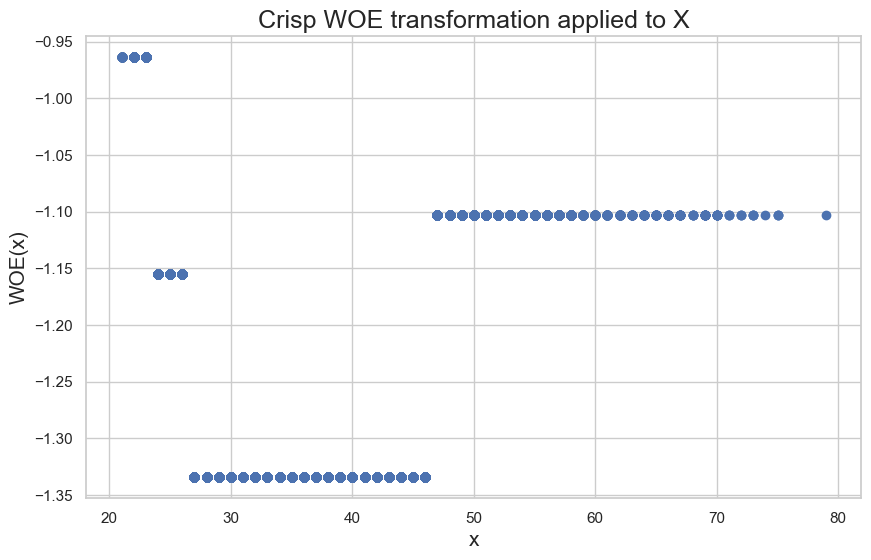

In [18]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))
plt.scatter(x_prueba, assign_woe(x_prueba, woe_values), color='b')

# Títulos y etiquetas
plt.title('Crisp WOE transformation applied to X', fontsize=18)
plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)

# Mostrar el gráfico
plt.show()

### Función de la transformación

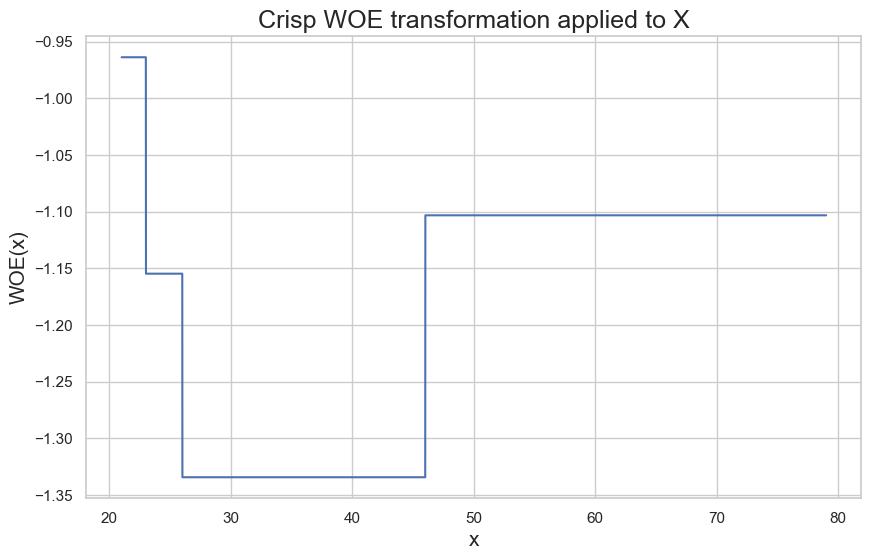

In [19]:
x_range = np.linspace(min(x_prueba), max(x_prueba), 10000)

plt.figure(figsize=(10, 6))
plt.plot(x_range, [assign_woe(xi, woe_values) for xi in x_range])

plt.title('Crisp WOE transformation applied to X', fontsize=18)
plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)

plt.grid(True)
plt.show()

## Transformación Crisp-Fuzzy WOE

### A los datos

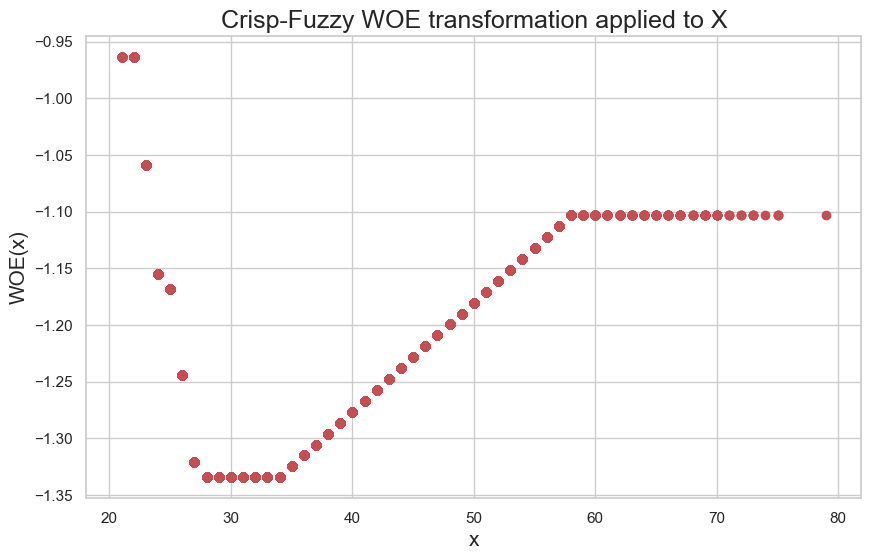

In [20]:
x_woe_and = np.array([fuzzy_woe_fixed_alfas['woe_function'](xi) for xi in x_prueba]).reshape(-1,1)
x_woe_and_range = np.array([fuzzy_woe_fixed_alfas['woe_function'](xi) for xi in x_range]).reshape(-1,1)

# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))
plt.scatter(x_prueba, x_woe_and, color='r')

# Títulos y etiquetas
plt.title('Crisp-Fuzzy WOE transformation applied to X', fontsize=18)
plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)

# Mostrar el gráfico
plt.show()

### Función de la transformación

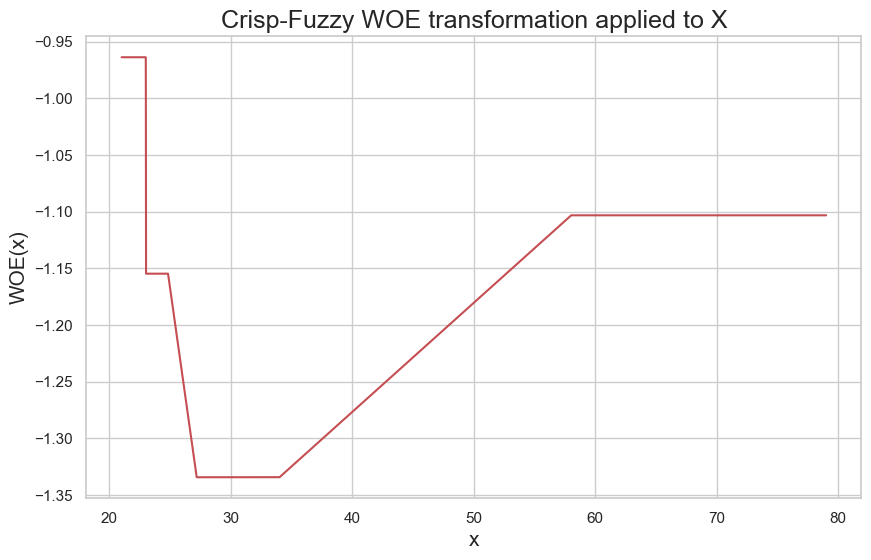

In [21]:
plt.figure(figsize=(10, 6))
plt.plot(x_range, [fuzzy_woe_fixed_alfas['woe_function'](xi) for xi in x_range], color='r')

# Títulos y etiquetas
plt.title('Crisp-Fuzzy WOE transformation applied to X', fontsize=18)
plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)

plt.grid(True)
plt.show()

### Grado de pertenencia de cada x a cada hoja con su valor WOE asociado

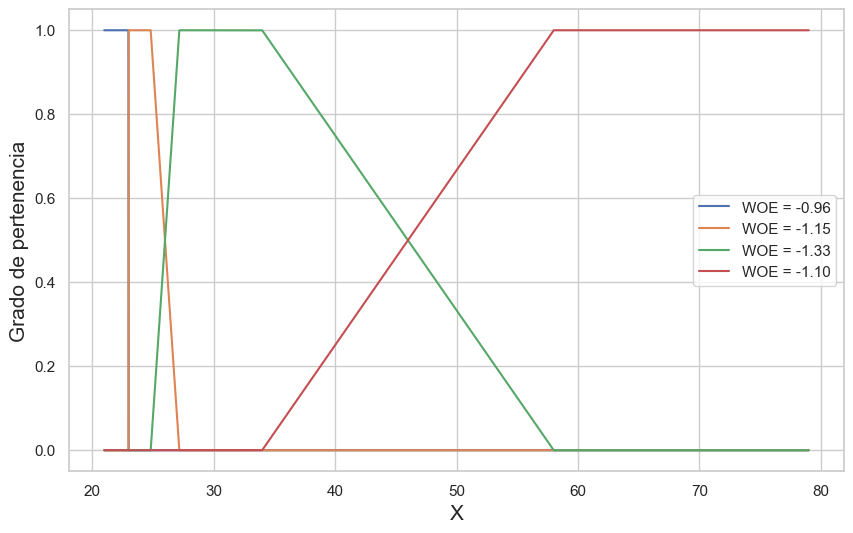

In [22]:
plot_grados_pertenencia_fuzzy_woe_fixed_alfas(fuzzy_woe_fixed_alfas, x_range)

## Transformación Fuzzy WOE

### A los datos

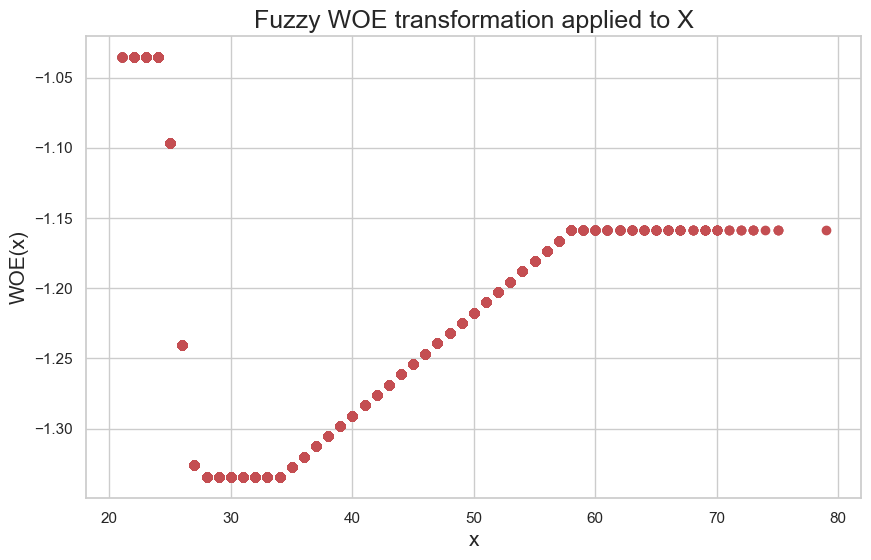

In [23]:
#Cálculo de las fuzzy_woe de esta variable

x_woe_ad = fdt.predict_fuzzy_woe(x_prueba)
x_woe_ad = np.array(x_woe_ad).reshape(-1,1)

x_woe_ad_range = fdt.predict_fuzzy_woe(x_range)
x_woe_ad_range = np.array(x_woe_ad_range).reshape(-1,1)

# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))
plt.scatter(x_prueba, x_woe_ad, color='r')

# Títulos y etiquetas
plt.title('Fuzzy WOE transformation applied to X', fontsize=18)
plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)

# Mostrar el gráfico
plt.show()

### Función de la transformación

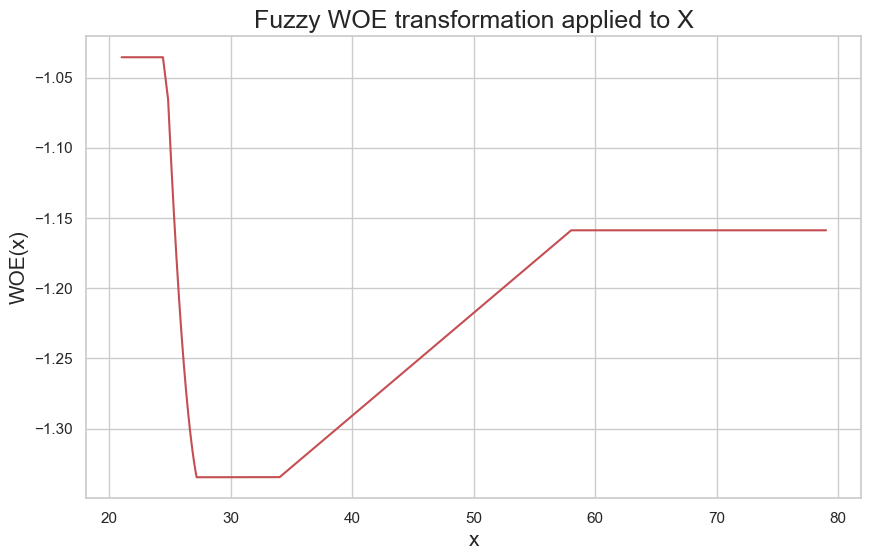

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(x_range, x_woe_ad_range, color='r')

# Títulos y etiquetas
plt.title('Fuzzy WOE transformation applied to X', fontsize=18)
plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)

plt.grid(True)
plt.show()

### Grado de pertenencia de cada x a cada hoja con su valor WOE asociado

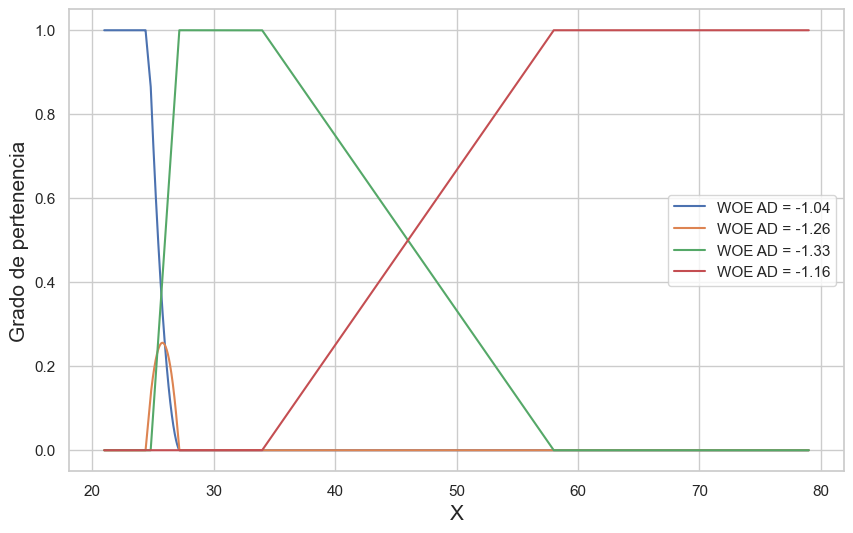

In [25]:
plot_membership_functions(fdt, x_range)

## Las tres transformaciones

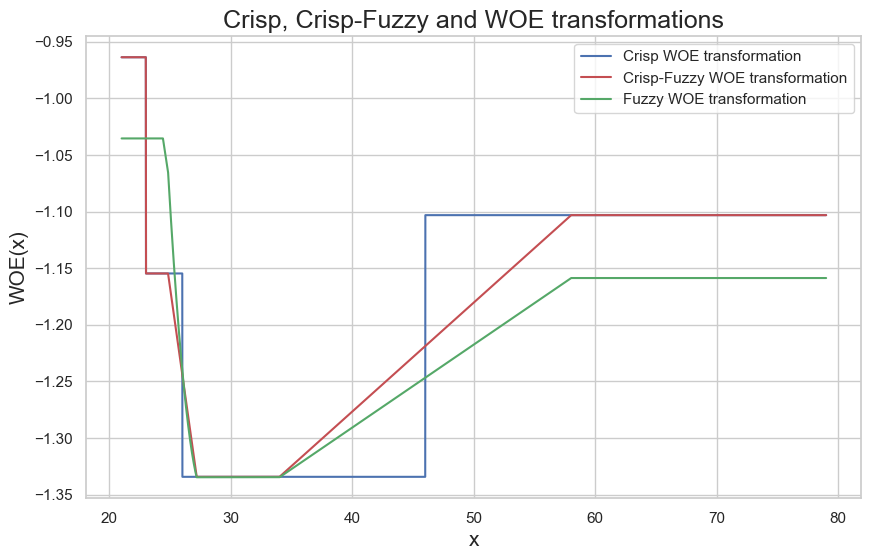

In [63]:
plt.figure(figsize=(10, 6))

plt.plot(x_range, [assign_woe(xi, woe_values) for xi in x_range], color='b', label='Crisp WOE transformation')
plt.plot(x_range, [fuzzy_woe_fixed_alfas['woe_function'](xi) for xi in x_range], color='r', label='Crisp-Fuzzy WOE transformation')
plt.plot(x_range, x_woe_ad_range, color='g', label='Fuzzy WOE transformation')

plt.legend()

plt.xlabel('x', fontsize=15)
plt.ylabel('WOE(x)', fontsize=15)
plt.title('Crisp, Crisp-Fuzzy and WOE transformations', fontsize=18)
plt.grid(True)
plt.show()

## Aplicación de una regresión logística: datos originales, transformación WOE nítida y transformación WOE difusa

### Datos originales

In [27]:
# Crear el modelo de regresión logística
modelo = LogisticRegression(penalty=None)

# Ajustar el modelo con los datos de entrenamiento
modelo.fit(x_prueba.reshape(-1, 1), y_prueba)

# Predecir en los datos de prueba
predicciones = modelo.predict(x_prueba.reshape(-1, 1))

# Evaluar el modelo
accuracy = modelo.score(x_prueba.reshape(-1, 1), y_prueba)
print("Exactitud del modelo:", accuracy)

# Predecir probabilidades en lugar de clases
predicciones_prob = modelo.predict_proba(x_prueba.reshape(-1, 1))[:, 1]
predicciones_prob_range = modelo.predict_proba(x_range.reshape(-1, 1))[:, 1]

# Calcular el AUC
auc_orig = roc_auc_score(y_prueba, predicciones_prob)
print("Área bajo la curva ROC (AUC):", auc_orig)

Exactitud del modelo: 0.7788
Área bajo la curva ROC (AUC): 0.5035788181103027


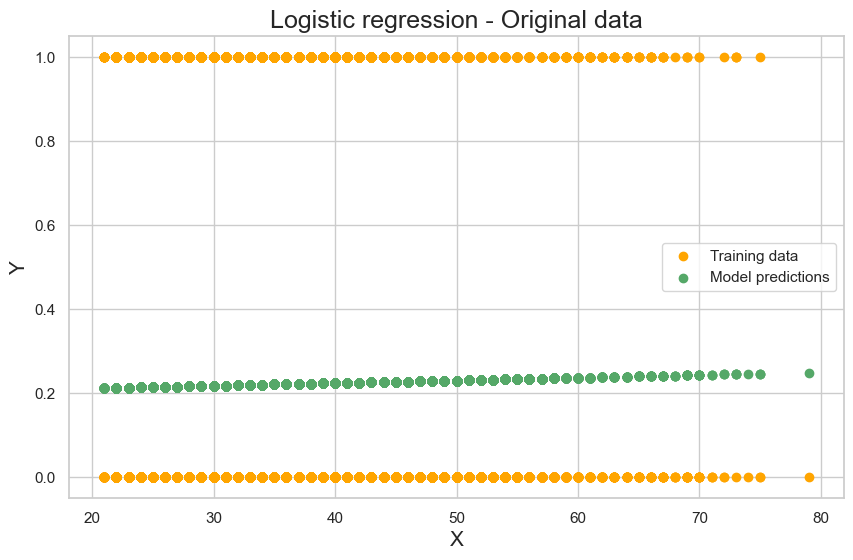

In [28]:
# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob, color='g', label='Model predictions')

# Añadir etiquetas y leyenda
plt.xlabel('X', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - Original data', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

In [29]:
modelo.coef_

array([[0.00360674]])

In [30]:
modelo.intercept_

array([-1.3869818])

### Transformación Crisp WOE

In [31]:
x_woe = assign_woe(x_prueba, woe_values).reshape(-1, 1)
x_woe_range = assign_woe(x_range, woe_values).reshape(-1, 1)

In [32]:
# Crear el modelo de regresión logística
modelo = LogisticRegression(penalty=None)

# Ajustar el modelo con los datos de entrenamiento
modelo.fit(x_woe, y_prueba)

# Predecir en los datos de prueba
predicciones = modelo.predict(x_woe)

# Evaluar el modelo
accuracy = modelo.score(x_woe, y_prueba)
print("Exactitud del modelo:", accuracy)

# Predecir probabilidades en lugar de clases
predicciones_prob_woe = modelo.predict_proba(x_woe)[:, 1]
predicciones_prob_woe_range = modelo.predict_proba(x_woe_range)[:, 1]

# Calcular el AUC
auc_crisp_woe = roc_auc_score(y_prueba, predicciones_prob_woe)
print("Área bajo la curva ROC (AUC):", auc_crisp_woe)

Exactitud del modelo: 0.7788
Área bajo la curva ROC (AUC): 0.5273149141417752


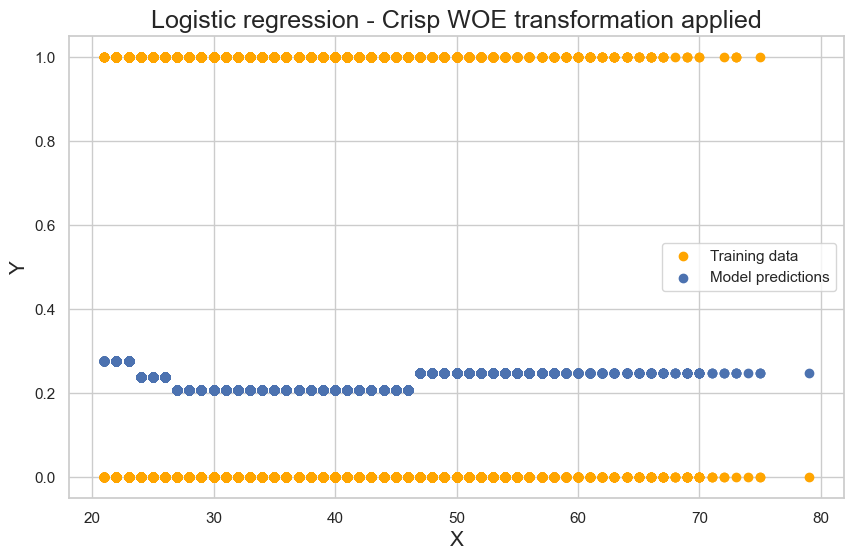

In [33]:
# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob_woe, color='b', label='Model predictions')

# Añadir etiquetas y leyenda
plt.xlabel('X', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - Crisp WOE transformation applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

In [34]:
beta_woe_crisp = modelo.coef_.item()
beta_woe_crisp

0.9985341770034641

In [35]:
alfa_woe_crisp = modelo.intercept_.item()
alfa_woe_crisp

-0.0020378396013016075

### Transformación Crisp-Fuzzy WOE

In [36]:
# Crear el modelo de regresión logística
modelo = LogisticRegression(penalty=None)

# Ajustar el modelo con los datos de entrenamiento
modelo.fit(x_woe_and, y_prueba)

# Predecir en los datos de prueba
predicciones = modelo.predict(x_woe_and)

# Evaluar el modelo
accuracy = modelo.score(x_woe_and, y_prueba)
print("Exactitud del modelo:", accuracy)

# Predecir probabilidades en lugar de clases
predicciones_prob_woe_and = modelo.predict_proba(x_woe_and)[:, 1]
predicciones_prob_woe_and_range = modelo.predict_proba(x_woe_and_range)[:, 1]

# Calcular el AUC
auc_crisp_fuzzy_woe = roc_auc_score(y_prueba, predicciones_prob_woe_and)
print("Área bajo la curva ROC (AUC):", auc_crisp_fuzzy_woe)

Exactitud del modelo: 0.7788
Área bajo la curva ROC (AUC): 0.5392857929733064


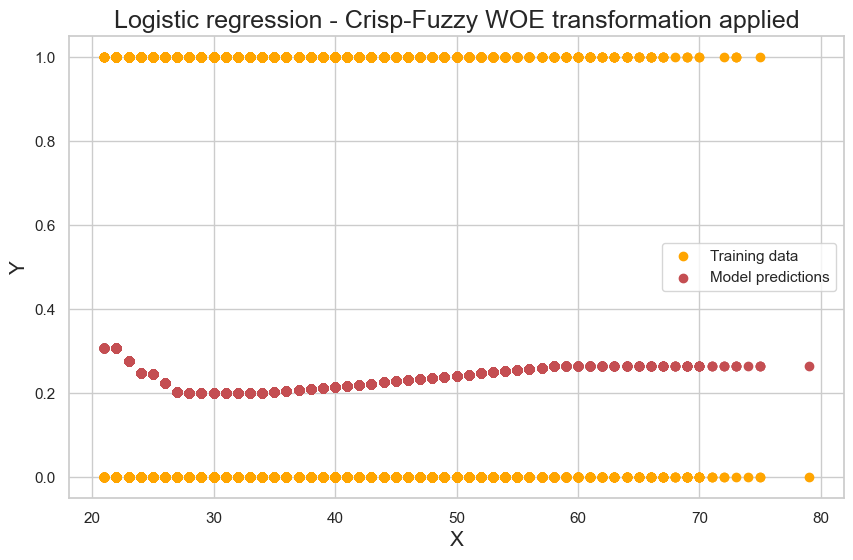

In [37]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob_woe_and, color='r', label='Model predictions')

# Añadir etiquetas y leyenda
plt.xlabel('X', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - Crisp-Fuzzy WOE transformation applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

In [38]:
beta_crisp_fuzzy_woe = modelo.coef_.item()
beta_crisp_fuzzy_woe

1.5411454649102525

In [39]:
alfa_crisp_fuzzy_woe = modelo.intercept_.item()
alfa_crisp_fuzzy_woe

0.6749626104607277

### Transformación Fuzzy WOE

In [40]:
# Crear el modelo de regresión logística
modelo = LogisticRegression(penalty=None)

# Ajustar el modelo con los datos de entrenamiento
modelo.fit(x_woe_ad, y_prueba)

# Predecir en los datos de prueba
predicciones = modelo.predict(x_woe_ad)

# Evaluar el modelo
accuracy = modelo.score(x_woe_ad, y_prueba)
print("Exactitud del modelo:", accuracy)

# Predecir probabilidades en lugar de clases
predicciones_prob_woe_ad = modelo.predict_proba(x_woe_ad)[:, 1]
predicciones_prob_woe_ad_range = modelo.predict_proba(x_woe_ad_range)[:, 1]

# Calcular el AUC
auc_fuzzy_woe = roc_auc_score(y_prueba, predicciones_prob_woe_ad)
print("Área bajo la curva ROC (AUC):", auc_fuzzy_woe)

Exactitud del modelo: 0.7788
Área bajo la curva ROC (AUC): 0.5387762069670459


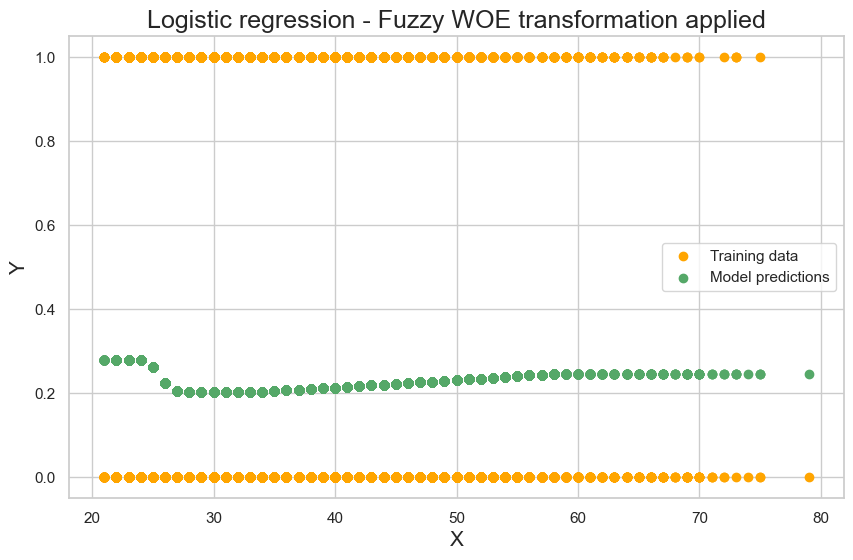

In [62]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob_woe_ad, color='g', label='Model predictions')

# Añadir etiquetas y leyenda
plt.xlabel('X', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - Fuzzy WOE transformation applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

In [42]:
beta_fuzzy_woe = modelo.coef_.item()
beta_fuzzy_woe

1.3965906908315284

In [43]:
alf_fuzzya_woe = modelo.intercept_.item()
alf_fuzzya_woe

0.4989898297806959

### Las tres

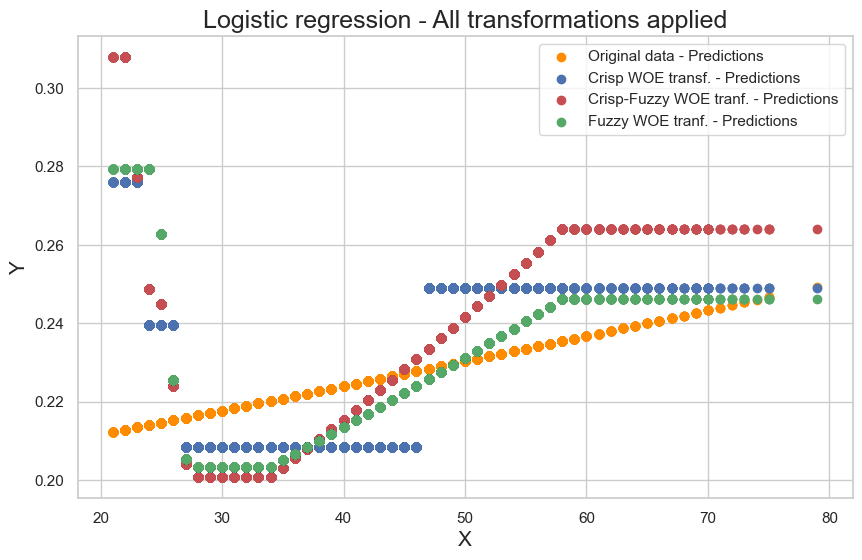

In [57]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
# plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob, color='darkorange', label='Original data - Predictions')
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob_woe, color='b', label='Crisp WOE transf. - Predictions')
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob_woe_and, color='r', label='Crisp-Fuzzy WOE tranf. - Predictions')
plt.scatter(x_prueba.reshape(-1, 1), predicciones_prob_woe_ad, color='g', label='Fuzzy WOE tranf. - Predictions')

# Añadir etiquetas y leyenda
plt.xlabel('X', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - All transformations applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

In [45]:
print("AUC datos originales:", auc_orig)
print("AUC transformación Crisp WOE:", auc_crisp_woe)
print("AUC transformación Crisp WOE:", auc_crisp_fuzzy_woe)
print("AUC transformación WOE difusa:", auc_fuzzy_woe)

AUC datos originales: 0.5035788181103027
AUC transformación Crisp WOE: 0.5273149141417752
AUC transformación Crisp WOE: 0.5392857929733064
AUC transformación WOE difusa: 0.5387762069670459


### Las tres transformaciones aplicadas a una malla de valores para hacer las funciones completas

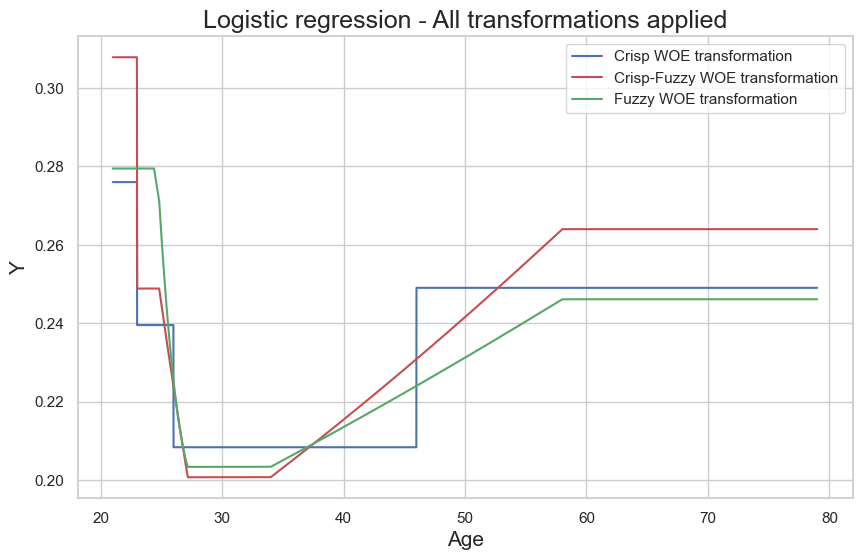

In [58]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
# plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
# plt.plot(x_range.reshape(-1, 1), predicciones_prob_range, color='g', label='Original data')
plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_range, color='b', label='Crisp WOE transformation')
plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_and_range, color='r', label='Crisp-Fuzzy WOE transformation')
plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_ad_range, color='g', label='Fuzzy WOE transformation')

# Añadir etiquetas y leyenda
plt.xlabel('Age', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - All transformations applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

### Datos originales con la transformación Crisp WOE

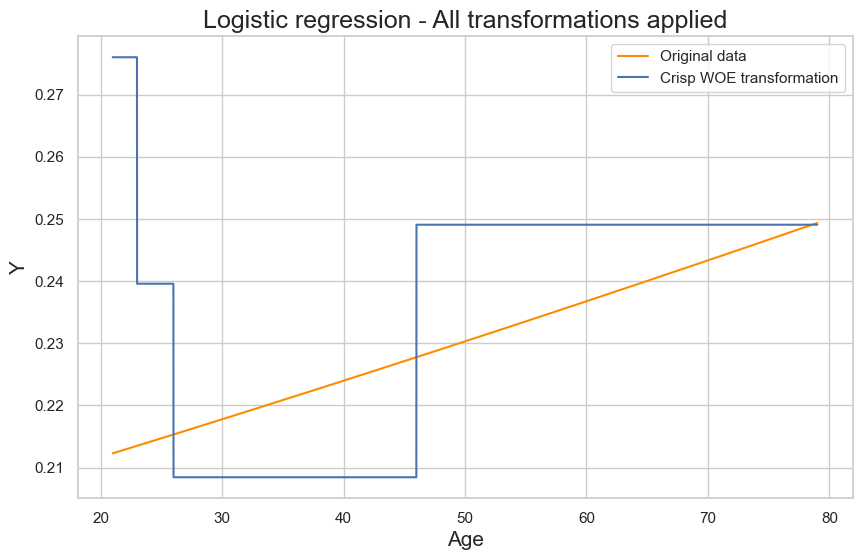

In [59]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Plot de los datos de entrenamiento
# plt.scatter(x_prueba.reshape(-1, 1), y_prueba, color='orange', label='Training data')

# Predicciones del modelo en los datos de entrenamiento
plt.plot(x_range.reshape(-1, 1), predicciones_prob_range, color='darkorange', label='Original data')
plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_range, color='b', label='Crisp WOE transformation')
# plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_and_range, color='r', label='Crisp-Fuzzy WOE transformation')
# plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_ad_range, color='grey', label='Fuzzy WOE transformation')

# Añadir etiquetas y leyenda
plt.xlabel('Age', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - All transformations applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

## Mismos dos gráficos que antes, con saltos en la Crisp WOE

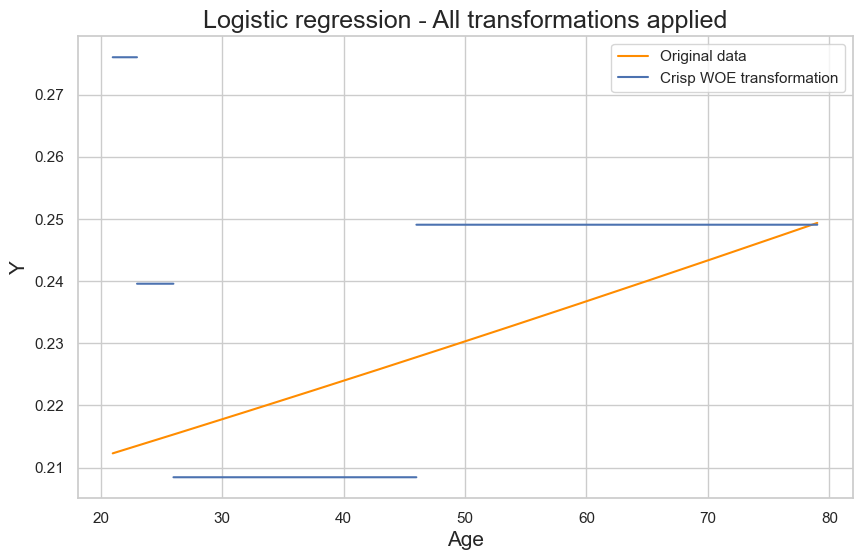

In [60]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Preparar los datos de 'Crisp WOE transformation' sin líneas verticales en los saltos
x_woe = x_range.ravel()
y_woe = np.asarray(predicciones_prob_woe_range, dtype=float).ravel()

# Detectar dónde cambia el valor de y (o usa un umbral pequeño si hay decimales flotantes)
saltos = np.where(~np.isclose(np.diff(y_woe), 0, atol=1e-12))[0] + 1

# Insertar NaN justo antes de cada salto para cortar el trazo
x_woe_plot = np.insert(x_woe, saltos, np.nan)
y_woe_plot = np.insert(y_woe, saltos, np.nan)

# Predicciones del modelo en los datos de entrenamiento
plt.plot(x_range.reshape(-1, 1), predicciones_prob_range, color='darkorange', label='Original data')
plt.plot(x_woe_plot, y_woe_plot, color='b', label='Crisp WOE transformation')

# Añadir etiquetas y leyenda
plt.xlabel('Age', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - All transformations applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

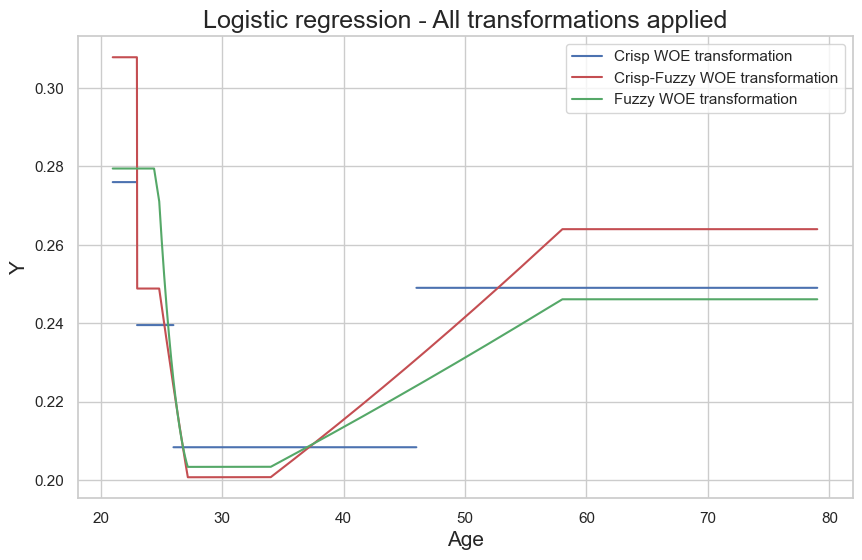

In [61]:
# Configuración de seaborn para mejorar la estética de los gráficos
sns.set(style="whitegrid")

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))

# Preparar los datos de 'Crisp WOE transformation' sin líneas verticales en los saltos
x_woe = x_range.ravel()
y_woe = np.asarray(predicciones_prob_woe_range, dtype=float).ravel()

# Detectar dónde cambia el valor de y (o usa un umbral pequeño si hay decimales flotantes)
saltos = np.where(~np.isclose(np.diff(y_woe), 0, atol=1e-12))[0] + 1

# Insertar NaN justo antes de cada salto para cortar el trazo
x_woe_plot = np.insert(x_woe, saltos, np.nan)
y_woe_plot = np.insert(y_woe, saltos, np.nan)

# Predicciones del modelo en los datos de entrenamiento
# plt.plot(x_range.reshape(-1, 1), predicciones_prob_range, color='g', label='Original data')
plt.plot(x_woe_plot, y_woe_plot, color='b', label='Crisp WOE transformation')
plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_and_range, color='r', label='Crisp-Fuzzy WOE transformation')
plt.plot(x_range.reshape(-1, 1), predicciones_prob_woe_ad_range, color='g', label='Fuzzy WOE transformation')

# Añadir etiquetas y leyenda
plt.xlabel('Age', fontsize=15)
plt.ylabel('Y', fontsize=15)
plt.title('Logistic regression - All transformations applied', fontsize=18)
plt.legend()

# Mostrar el gráfico
plt.show()

# No ejecutar de aqui en adelante, esto queda fuera del alcance

## De probabilidad a score. WOE nítida y difusa

In [751]:
x_woe_crisp_full_range = assign_woe(x_range, woe_values)
x_woe_fuzzy_full_range = np.array([fuzzy_woe_fixed_alfas['woe_function'](xi) for xi in x_range])

In [752]:
def calcular_score_vectorizado(woe_series, beta, alpha, n, factor, offset):
    """
    Aplica la fórmula de Scorecard a toda una columna o vector de WOEs.
    """
    # Términos constantes (se calculan una sola vez)
    term_intercepto = alpha / n
    term_offset = offset / n
    
    # Aplicación vectorizada: Pandas/Numpy aplica esto a cada elemento automáticamente
    # Fórmula: SCORE = (-WOE * beta + alpha/n) * factor + offset/n
    scores = ((-woe_series * beta) + term_intercepto) * factor + term_offset
    
    return scores

In [753]:
woe_series = x_woe_crisp_full_range
beta = beta_woe_crisp
alpha = alfa_woe_crisp
n_variables = 1
factor = 20 / np.log(2)
# Por cada 20 puntos que aumenta el score, la probabilidad de que un cliente sea bueno (odds) se duplica
offset = 100

In [754]:
score_crisp_woe = calcular_score_vectorizado(
    woe_series,
    beta, 
    alpha, 
    n_variables, 
    factor, 
    offset
)

In [755]:
woe_series = x_woe_fuzzy_full_range
beta = beta_woe_fuzzy
alpha = alfa_woe_fuzzy
n_variables = 1
factor = 20 / np.log(2)
# Por cada 20 puntos que aumenta el score, la probabilidad de que un cliente sea bueno (odds) se duplica
offset = 100

In [756]:
score_fuzzy_woe = calcular_score_vectorizado(
    woe_series,
    beta, 
    alpha, 
    n_variables, 
    factor, 
    offset
)

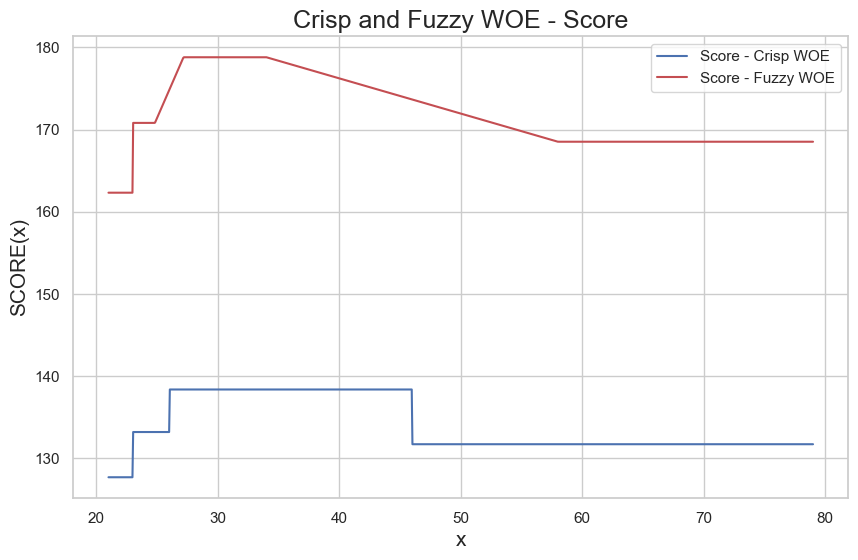

In [757]:
plt.figure(figsize=(10, 6))

plt.plot(x_range, score_crisp_woe, color='b', label='Score - Crisp WOE')
plt.plot(x_range, score_fuzzy_woe, color='r', label='Score - Fuzzy WOE')

plt.legend()

plt.xlabel('x', fontsize=15)
plt.ylabel('SCORE(x)', fontsize=15)
plt.title('Crisp and Fuzzy WOE - Score', fontsize=18)
plt.grid(True)
plt.show()

### Para hacer esto comparable hay que coger el mismo beta y alfa. Cojo el del modelo crisp - PREGUNTAR QUÉ HACER CON ESTO

In [758]:
woe_series = x_woe_fuzzy_full_range
beta = beta_woe_crisp
alpha = alfa_woe_crisp
n_variables = 1
factor = 20 / np.log(2)
# Por cada 20 puntos que aumenta el score, la probabilidad de que un cliente sea bueno (odds) se duplica
offset = 100

In [759]:
score_fuzzy_woe_2 = calcular_score_vectorizado(
    woe_series,
    beta, 
    alpha, 
    n_variables, 
    factor, 
    offset
)

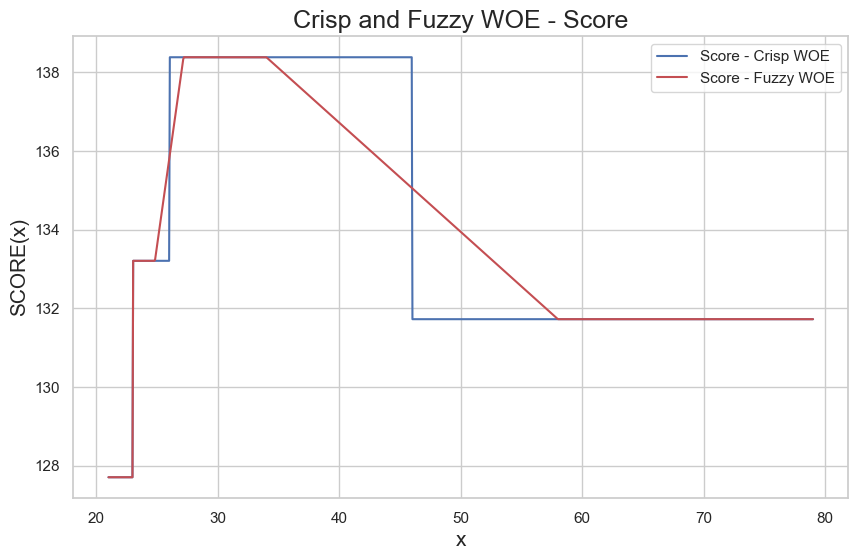

In [760]:
plt.figure(figsize=(10, 6))

plt.plot(x_range, score_crisp_woe, color='b', label='Score - Crisp WOE')
plt.plot(x_range, score_fuzzy_woe_2, color='r', label='Score - Fuzzy WOE')

plt.legend()

plt.xlabel('x', fontsize=15)
plt.ylabel('SCORE(x)', fontsize=15)
plt.title('Crisp and Fuzzy WOE - Score', fontsize=18)
plt.grid(True)
plt.show()